
Data: US Social Security Administration (SSA), national baby names 1880–2025
(https://www.ssa.gov/oact/babynames/limits.html). One file `yobYYYY.txt` per year with columns
`name, sex, count`; names given to fewer than 5 babies in a year are not published.


In [2]:
%pip install -q numpy pandas scipy matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import io, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [4]:

def load_names(zip_path="/content/drive/MyDrive/names.zip", data_dir="data/names"):
    data_dir = Path(data_dir)
    if not any(data_dir.glob("yob*.txt")):
        data_dir.mkdir(parents=True, exist_ok=True)
        zipfile.ZipFile(zip_path).extractall(data_dir)

    frames = []
    for path in sorted(data_dir.glob("yob*.txt")):
        df = pd.read_csv(path, header=None, names=["name", "sex", "count"])
        df["year"] = int(path.stem[3:])
        frames.append(df)
    names = pd.concat(frames, ignore_index=True)

    names["rank"] = (names.groupby(["year", "sex"])["count"].rank(method="first", ascending=False).astype(int))
    names["share"] = names["count"] / names.groupby(["year", "sex"])["count"].transform("sum")
    return names

names = load_names(zip_path="names.zip")
print(f"{len(names):,} rows, years {names.year.min()}–{names.year.max()}")
print(names.groupby("sex").size()) #кількість імен а не дітей
names[names.year == 2025].groupby("sex").head(5)

2,181,032 rows, years 1880–2025
sex
F    1280901
M     900131
dtype: int64


,name,sex,count,year,rank,share
2149805,Olivia,F,13544,2025,1,0.008427
2149806,Charlotte,F,13400,2025,2,0.008337
2149807,Emma,F,12754,2025,3,0.007935
2149808,Amelia,F,12699,2025,4,0.007901
2149809,Sophia,F,12561,2025,5,0.007815
2167102,Liam,M,20818,2025,1,0.012188
2167103,Noah,M,20358,2025,2,0.011919
2167104,Oliver,M,14939,2025,3,0.008746
2167105,Theodore,M,13355,2025,4,0.007819
2167106,Henry,M,12020,2025,5,0.007037


## 2. Name diversity over time

We measure how concentrated or diverse names are in each year, separately for girls and boys.

- **Shannon entropy.** If $p_i$ is the share of babies given name $i$ in a year, then
  $H = -\sum_i p_i \log_2 p_i$ (in bits). $H$ is larger when births are spread over many
  names with similar popularity. $2^H$ can be read as the "effective number" of equally
  popular names.
- **Top-10 share.** The percentage of all babies of that sex who received one of the 10 most
  popular names. It is a simple and robust measure of concentration at the top.

In [5]:
def diversity_measures(group):
    x = group['count'].to_numpy(dtype=float)
    p = x / x.sum()
    return pd.Series({
        'births': x.sum(),
        'distinct names': len(x),
        'entropy, bits': -(p * np.log2(p)).sum(),
        'top-10 share, %': 100*np.sort(x)[::-1][:10].sum() / x.sum(),
    })

diversity = (names.groupby(['sex', 'year'])[['count']]
             .apply(diversity_measures)
             .reset_index())
diversity.head()

,sex,year,births,distinct names,"entropy, bits","top-10 share, %"
0,F,1880,90994.0,942.0,7.591849,24.648878
1,F,1881,91953.0,938.0,7.599520,24.154731
2,F,1882,107847.0,1028.0,7.638406,23.941324
3,F,1883,112320.0,1054.0,7.678668,23.422365
4,F,1884,129019.0,1172.0,7.733801,23.143878


In [6]:
check = diversity[diversity.year.isin([1950, 1980, 2000, 2010, 2025])]
check.pivot(index="year", columns="sex",
            values=["top-10 share, %", "entropy, bits"]).round(2)

top-10 share, %        entropy, bits       
sex                F      M             F      M
year                                            
1950           24.10  33.80          8.28   7.48
1980           17.10  23.58          9.47   8.26
2000           10.22  13.37         10.44   9.38
2010            8.87   8.97         10.99  10.00
2025            6.99   7.98         11.05  10.43

In 1950, 33.8% of boys and 24.1% of girls received a top-10 name; in 2025 it was only 8.0% and  7.0%. Over the same period entropy rose from 7.48 to 10.43 bits for boys and from 8.28 to 11.05 bits for girls, so the 'effective number' of names grew roughly 8 times for boys ($2^{10.43-7.48} \approx 7.7$) and 7 times for girls.

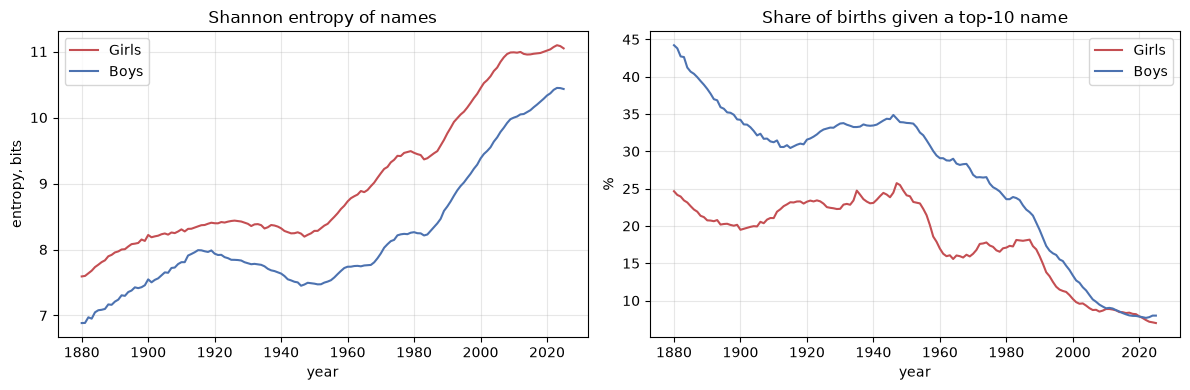

In [7]:
COLORS = {"F": "#C44E52", "M": "#4C72B0"}
LABELS = {"F": "Girls", "M": "Boys"}

def plot_diversity(diversity, start_year=1880):
    d = diversity[diversity.year >= start_year]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for sex in ["F", "M"]:
        s = d[d.sex == sex]
        axes[0].plot(s["year"], s["entropy, bits"], color=COLORS[sex], label=LABELS[sex])
        axes[1].plot(s["year"], s["top-10 share, %"], color=COLORS[sex], label=LABELS[sex])
    axes[0].set_title("Shannon entropy of names")
    axes[0].set_ylabel("entropy, bits")
    axes[1].set_title("Share of births given a top-10 name")
    axes[1].set_ylabel("%")
    for ax in axes:
        ax.set_xlabel("year"); ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

plot_diversity(diversity)

**Long-run trend.** Diversity was roughly flat or even falling until about 1950 (for boys the top-10 share actually rose from about 31% to 35% in 1915–1947). After 1950 entropy rises
steadily and the top-10 share falls sharply for both sexes.


**Girls' names have been more diverse for the whole period**: girls' entropy is higher
in every year. Boys have been catching up, and by about 2010 the top-10 shares of the two
sexes became almost equal.


**The trend is not linear.** There are periods of stagnation and fast growth, so a single
straight line over 1880–2025 would describe the data poorly.





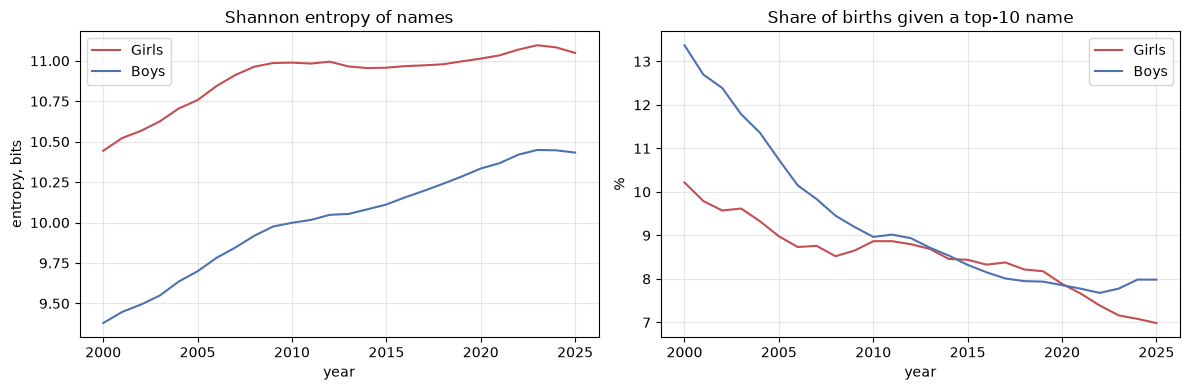

entropy, bits         top-10 share, %       
sex              F       M               F      M
year                                             
2010        10.989   9.999           8.865  8.965
2011        10.983  10.016           8.867  9.018
2012        10.994  10.048           8.797  8.934
2013        10.965  10.053           8.689  8.718
2014        10.955  10.082           8.458  8.536
2015        10.957  10.112           8.439  8.322
2016        10.967  10.156           8.327  8.152
2017        10.972  10.196           8.377  8.009
2018        10.978  10.240           8.217  7.949
2019        10.997  10.285           8.175  7.937
2020        11.013  10.334           7.886  7.857
2021        11.034  10.367           7.660  7.773
2022        11.069  10.420           7.389  7.678
2023        11.096  10.449           7.161  7.776
2024        11.083  10.447           7.081  7.984
2025        11.049  10.433           6.985  7.983

In [8]:
plot_diversity(diversity, start_year=2000)
(diversity[diversity.year >= 2010]
 .pivot(index="year", columns="sex", values=["entropy, bits", "top-10 share, %"])
 .round(3))

**A closer look at the last 15 years.**


- **Girls:** entropy stayed almost flat from 2009 to 2018 (around 10.96–10.99 bits), then grew again to a maximum of 11.10 bits in 2023, and slightly decreased in 2024–2025.
- **Boys:** entropy kept growing every year until 2023 (10.45 bits), then also slightly decreased.
- **Boys' top-10 share** stopped falling around 2018 (about 7.9–8.0%) and even rose a little in 2024–2025.


So the strong upward trend in diversity may be slowing down. This motivates H2: instead of
only testing "entropy increases over time" (which is obvious from the plot), we can test
whether the slope in recent years is significantly smaller than before.